# Chapter 68: Public Goods, Free Riding, Clubs, and Collective Funding

This notebook reruns four worked examples from the chapter: the Samuelson test for a shared alert network, quadratic funding with a limited pool, the best size of a club, and a grant for a discovery with spillovers. Every example is hypothetical, as in the book; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def vline(ax, x, text=None, col="grey", style="dashed", y_frac=0.95, ha="left", lw=1.4):
    """Vertical reference line with an optional label near the top of the axes."""
    ax.axvline(x, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x, y_frac), xycoords=("data", "axes fraction"), xytext=(5 if ha == "left" else -5, 0),
                    textcoords="offset points", ha=ha, va="top", color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def bar_compare(ax, names, values, colors=None, value_labels=None, ylabel="Value", xlabel="Item", fmt=None,
                zero_line=True):
    """Labelled vertical bars, one per name; each bar carries its value label.

    ``value_labels`` gives the text over each bar (else ``fmt(v)`` or '{:,.2f}').
    Negative bars are allowed; labels go below them.
    """
    values = [float(v) for v in values]
    colors = colors or [color(i) for i in range(len(values))]
    xs = np.arange(len(values))
    ax.bar(xs, values, color=[color(c) for c in colors], width=0.6)
    ax.set_xticks(xs, names)
    lo, hi = min(0.0, min(values)), max(0.0, max(values))
    span = (hi - lo) or 1.0
    ax.set_ylim(lo - (0.14 * span if lo < 0 else 0), hi + 0.16 * span)
    for x, v, i in zip(xs, values, range(len(values))):
        text = value_labels[i] if value_labels else (fmt(v) if fmt else f"{v:,.2f}")
        ax.annotate(text, (x, v), xytext=(0, 4 if v >= 0 else -4), textcoords="offset points", ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=LABEL_SIZE, color=PALETTE["ink"])
    if zero_line and lo < 0:
        ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_ylabel(ylabel)
    ax.set_xlabel(xlabel)
    return ax


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def money(value, digits=2, comma=True):
    """Dollar amount: money(1444.444) -> '$1,444.44'; money(-480, 0) -> '-$480'."""
    text = num(value, digits, comma)
    return f"-${text[1:]}" if text.startswith("-") else f"${text}"


def plural(count, singular, plural_form=None):
    """'1 trip', '3 trips', '0 trips'. Count is printed as an integer when whole."""
    word = singular if count == 1 else (plural_form or singular + "s")
    shown = str(int(count)) if float(count).is_integer() else str(count)
    return f"{shown} {word}"


def samuelson_test(values, mc):
    """Samuelson test for one more unit: sum of marginal values against marginal cost.

    Principle: samuelson-condition-for-public-goods. Book (ch068): 22 + 15 + 11 + 8 = 56 > 50 (surplus 6);
    16 + 12 + 9 + 6 = 43 < 50; with a 5 spillover and cost 58, 61 > 58.
    Returns dict with MB, surplus MB - mc, passes, and the largest single value.
    """
    mb = sum(values)
    return {"MB": mb, "surplus": mb - mc, "passes": mb > mc, "max_single": max(values)}


def qf_target(contributions):
    """Quadratic-funding target F = (sum of sqrt c_i)^2 and match F - sum c_i.

    Principle: quadratic-funding. Book (ch068): one 144 gives 144 (match 0); four 36 give
    (4 x 6)^2 = 576 (match 432); nine 16 give (9 x 4)^2 = 1,296 (match 1,152).
    """
    root_sum = sum(math.sqrt(c) for c in contributions)
    target = root_sum ** 2
    return {"root_sum": root_sum, "target": target, "private": sum(contributions), "match": target - sum(contributions)}


def qf_scale(matches, pool):
    """Scale desired matches down proportionally when they exceed the pool (beta = min(1, pool / total)).

    Principle: quadratic-funding. Book (ch068): matches 432 and 1,152, pool 600: beta = 600/1,584 = 0.3788,
    paid 163.64 and 436.36.
    """
    total = sum(matches)
    beta = 1.0 if total <= pool else pool / total
    return {"total": total, "beta": beta, "paid": [m * beta for m in matches]}


def club_utility(n, B, a, C):
    """Member utility u(n) = B - a n^2 - C / n. Principle: optimal-club-size.

    Book (ch068): B = 2,100, a = 0.12, C = 72,000: u(66) = 486.37, u(67) = 486.69, u(68) = 486.30, u(60) = 468.
    """
    return B - a * n * n - C / n


def optimal_club_size(a, C, B=None):
    """Continuous optimum n* = (C / (2a))^(1/3) from 2 a n = C / n^2, and the best integer neighbour.

    Principle: optimal-club-size. Book (ch068): n^3 = 300,000, n* = 66.94, best integer 67.
    If B is given the best integer is chosen by comparing u at floor and ceiling of n*.
    """
    n_star = (C / (2 * a)) ** (1 / 3)
    lo, hi = math.floor(n_star), math.ceil(n_star)
    if B is None:
        best = hi if n_star - lo >= 0.5 else lo
    else:
        best = hi if club_utility(hi, B, a, C) > club_utility(lo, B, a, C) else lo
    return {"n_star": n_star, "n_cubed": C / (2 * a), "best": best}


def spillover_gap(C, P, S, d=0.0):
    """Private and social net values of a project with uncollectible spillover S net of diffusion cost d.

    Principle: public-goods-spillovers. Book (ch068): C = 420,000, P = 270,000, S = 230,000: private net
    -150,000, social net 80,000, grant C - P = 150,000; with d = 110,000 social net is -30,000.
    """
    social = P + S - d - C
    return {"private_net": P - C, "social_value": P + S - d, "social_net": social, "grant": max(0.0, C - P),
            "grant_worthwhile": social > 0}


plt.rcParams.update(HOUSE_RC)


public = SimpleNamespace(samuelson_test=samuelson_test, qf_target=qf_target, qf_scale=qf_scale, club_utility=club_utility, optimal_club_size=optimal_club_size, spillover_gap=spillover_gap)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'samuelson-condition-for-public-goods': {'values_3': (22, 15, 11, 8),
                                          'values_4': (16, 12, 9, 6),
                                          'mc': 50,
                                          'MB_3': 56,
                                          'surplus_3': 6,
                                          'MB_4': 43,
                                          'mc_finance': 58,
                                          'spillover': 5,
                                          'MB_3_spill': 61},
 'quadratic-funding': {'private': 144,
                       'F_A': 144,
                       'M_A': 0,
                       'F_B': 576,
                       'M_B': 432,
                       'F_C': 1296,
                       'M_C': 1152,
                       'pool': 600,
                       'desired': 1584,
                       'beta': 0.3788,
                       'paid_B': 163.64,
                       'paid_C': 436.36},
 'optimal-club-size': {'C': 72000,
                       'B': 2100,
                       'a': 0.12,
                       'n_cubed': 300000,
                       'n_star': 66.94,
                       'u66': 486.37,
                       'u67': 486.69,
                       'u68': 486.3,
                       'u60': 468,
                       'best': 67},
 'public-goods-spillovers': {'C': 420000,
                             'P': 270000,
                             'S': 230000,
                             'V': 500000,
                             'private_net': -150000,
                             'social_net': 80000,
                             'grant': 150000,
                             'd': 110000,
                             'net_spill': 120000,
                             'social_value_d': 390000,
                             'shortfall_d': -30000},
 'constructed': {'samuelson-condition-for-public-goods': {'mc': [42]},
                 'quadratic-funding': {'n': [16], 'pool': [1000]},
                 'optimal-club-size': {'C': [48000, 96000], 'a': [0.08, 0.16]},
                 'public-goods-spillovers': {'S': [150000, 300000]}}}


def samuelson_picture(k="3", mc=50, s=0):
    bv = BV["samuelson-condition-for-public-goods"]
    vals = list(bv["values_3"] if k == "3" else bv["values_4"])
    parts = vals + ([s] if s else [])
    r = public.samuelson_test(parts, mc)
    fig, ax = new_figure()
    names = ["district 1", "district 2", "district 3", "district 4"] + (["inland spillover"] if s else [])
    cols = ["teal", "navy", "gold", "olive", "terracotta"]
    bottom = 0.0
    for v, n, c in zip(parts, names, cols):
        ax.bar([0], [v], bottom=bottom, color=PALETTE[c], width=0.55)
        ax.text(0, bottom + v / 2, f"{n}: {num(v, 0)}", ha="center", va="center", fontsize=10.5, color="white")
        bottom += v
    ax.annotate(f"sum {num(r['MB'], 0)}", (0.3, r["MB"]), xytext=(4, 0), textcoords="offset points", ha="left",
                va="center", fontsize=10.5, color=PALETTE["ink"],
                bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})
    ax.bar([1], [r["max_single"]], color=PALETTE["light"], width=0.55)
    ax.annotate(f"{num(r['max_single'], 0)}", (1, r["max_single"]), xytext=(0, 4), textcoords="offset points",
                ha="center", va="bottom", fontsize=10.5, color=PALETTE["ink"])
    hline(ax, mc, f"marginal cost {num(mc, 0)}", col="terracotta", x_frac=0.70, va="bottom")
    ax.set_xticks([0, 1], ["sum of marginal values", "largest single district"])
    ax.set_xlim(-0.6, 1.6)
    ax.set_ylim(0, 75)
    ax.set_ylabel("Dollars per storm for one more package")
    ax.set_xlabel(f"{'Third' if k == '3' else 'Fourth'} alert package")
    order = "third" if k == "3" else "fourth"
    sum_txt = " + ".join(num(v, 0) for v in parts)
    verdict = (f"{num(r['MB'], 0)} > {num(mc, 0)}, so the {order} package passes with surplus {num(r['surplus'], 0)}"
               if r["passes"] else
               f"{num(r['MB'], 0)} < {num(mc, 0)}, so the {order} package fails by {num(-r['surplus'], 0)}")
    metrics = {"Sum of marginal values": num(r["MB"], 0), "Marginal cost": num(mc, 0),
               "Surplus": num(r["surplus"], 0), "Largest single value": num(r["max_single"], 0),
               "Package": "passes" if r["passes"] else "fails"}
    steps = [f"MB = {sum_txt} = {num(r['MB'], 0)}",
             f"MB - MC = {num(r['MB'], 0)} - {num(mc, 0)} = {num(r['surplus'], 0)}",
             f"Largest single value {num(r['max_single'], 0)} < {num(mc, 0)}: no district buys alone"]
    interp = (f"The districts' marginal values{' plus the spillover' if s else ''} sum to {sum_txt} = "
              f"{num(r['MB'], 0)}. {verdict}. No district would pay {num(mc, 0)} alone: the largest single value "
              f"is {num(r['max_single'], 0)}.")
    alt = (f"Stacked bar of the marginal values for the {order} package summing to {num(r['MB'], 0)}, a bar for the "
           f"largest single value {num(r['max_single'], 0)}, and the marginal cost line at {num(mc, 0)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def qf_picture(n=4, pool=600):
    bv = BV["quadratic-funding"]
    total = bv["private"]
    each = total / n
    r = public.qf_target([each] * n)
    rb = public.qf_target([36] * 4)
    sc = public.qf_scale([rb["match"], r["match"]], pool)
    paid_b, paid_x = sc["paid"]
    fig, (ax, bx) = new_figure(ncols=2)
    ns = np.arange(1, 17)
    ax.plot(ns, 144 * ns, color=PALETTE["teal"], linewidth=2.0, marker="o", markersize=3.5)
    hline(ax, total, "private dollars 144", col="grey", x_frac=0.60, va="bottom")
    ax.plot([n, n], [total, r["target"]], color=PALETTE["gold"], linewidth=4, solid_capstyle="butt")
    mark(ax, n, r["target"], f"target {num(r['target'], 0)}, match {num(r['match'], 0)}", col="ink",
         dx=-8 if n > 8 else 8, dy=6, ha="right" if n > 8 else "left")
    ax.set_xlim(0, 17)
    ax.set_ylim(0, 2700)
    ax.set_xlabel("Number of equal donors (144 in total)")
    ax.set_ylabel("Funding target (sum of roots)^2")
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
    other = f"{n}-donor project"
    bar_compare(bx, ["B, desired", "B, paid", f"{plural(n, 'donor')},\ndesired", f"{plural(n, 'donor')},\npaid"],
                [rb["match"], paid_b, r["match"], paid_x], colors=["light", "navy", "light", "gold"],
                value_labels=[num(rb["match"]), num(paid_b), num(r["match"]), num(paid_x)],
                ylabel="Match", xlabel=f"Pool {num(pool, 0)} shared by B and the {other}")
    bx.set_ylim(0, 2550)
    bx.yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
    left = pool - sc["total"] * sc["beta"]
    metrics = {"Funding target": num(r["target"], 0), "Match": num(r["match"], 0),
               "Scaling factor beta": num(sc["beta"], 4), "B receives": num(paid_b),
               f"{n}-donor project receives": num(paid_x), "Pool left over": num(max(0.0, left))}
    root = math.sqrt(each)
    steps = [f"Each of {n} gives {num(each, 0)}; sqrt({num(each, 0)}) = {num(root, 0)}",
             f"F = ({n} x {num(root, 0)})^2 = {num(r['target'], 0)}; match = {num(r['target'], 0)} - 144 = "
             f"{num(r['match'], 0)}",
             f"Desired matches: 432 + {num(r['match'], 0)} = {num(sc['total'], 0)}"]
    if sc["beta"] < 1:
        steps += [f"beta = {num(pool, 0)} / {num(sc['total'], 0)} = {num(sc['beta'], 6)}",
                  f"B: 432 x {num(sc['beta'], 6)} = {num(paid_b)}; other: {num(r['match'], 0)} x "
                  f"{num(sc['beta'], 6)} = {num(paid_x)}"]
        pool_txt = (f"The desired matches total {num(sc['total'], 0)}, more than the pool of {num(pool, 0)}, so both "
                    f"are scaled by {num(sc['beta'], 4)}: B receives {num(paid_b)} and the {other} {num(paid_x)}.")
    elif abs(sc["total"] - pool) < 1e-9:
        steps += [f"{num(sc['total'], 0)} = {num(pool, 0)}, so beta = 1 and nothing is left over"]
        pool_txt = (f"The desired matches total {num(sc['total'], 0)}, exactly the pool of {num(pool, 0)}, so both are "
                    f"paid in full and the pool is used up with nothing left over.")
    else:
        steps += [f"{num(sc['total'], 0)} < {num(pool, 0)}, so beta = 1 and {num(left)} is left over"]
        pool_txt = (f"The desired matches total {num(sc['total'], 0)}, within the pool of {num(pool, 0)}, so both are "
                    f"paid in full and {num(left)} is left over.")
    if abs(r["match"] - rb["match"]) < 1e-9:
        pool_txt += (f" The {other} is identical to B (four donors of 36), so the two tie and receive the same "
                     f"{num(paid_b)}.")
    interp = (f"{n} {'donor gives' if n == 1 else 'donors give'} {num(each, 0)} "
              f"{'' if n == 1 else 'each '}for 144 in total. The target is ({n} x {num(root, 0)})^2 = "
              f"{num(r['target'], 0)}, so the match is {num(r['match'], 0)}: holding private money fixed, the target "
              f"grows in proportion to the number of donors. {pool_txt}")
    alt = (f"Left: the funding target 144 n rises in a straight line with the number of donors; at {n} it is "
           f"{num(r['target'], 0)}. Right: desired and paid matches for B ({num(paid_b)} paid) and the {other} "
           f"({num(paid_x)} paid) from a pool of {num(pool, 0)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def club_picture(cost=72000, a=0.12):
    B = BV["optimal-club-size"]["B"]
    o = public.optimal_club_size(a, cost, B)
    lo, hi = math.floor(o["n_star"]), math.ceil(o["n_star"])
    best = o["best"]
    u_best = public.club_utility(best, B, a, cost)
    ns = np.linspace(30, 110, 300)
    us = [public.club_utility(x, B, a, cost) for x in ns]
    fig, ax = new_figure()
    ax.plot(ns, us, color=PALETTE["teal"], linewidth=2.2)
    vline(ax, o["n_star"], f"n* = {num(o['n_star'])}", col="grey", y_frac=0.97,
          ha="right" if o["n_star"] > 75 else "left")
    mark(ax, best, u_best, f"best: {best} members, u = {num(u_best)}", col="terracotta", dx=0, dy=-12, ha="center",
         va="top")
    hline(ax, 0, None, col="grey", style="solid", lw=1)
    top, bot = max(us), min(us)
    span = top - bot
    ax.set_ylim(bot - 0.08 * span, top + 0.22 * span)
    ax.set_xlim(30, 110)
    ax.set_xlabel("Members n")
    ax.set_ylabel("Net benefit per member u(n)")
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
    viable = u_best > 0

    def line(n):
        cg, sh = a * n * n, cost / n
        return f"u({n}) = 2,100 - {num(cg)} - {num(sh)} = {num(public.club_utility(n, B, a, cost))}"

    metrics = {"n^3 = C / 2a": num(o["n_cubed"], 0), "Continuous optimum n*": num(o["n_star"]),
               "Best whole club": f"{best} members", "Member net benefit u": num(u_best),
               "Worth joining": "yes" if viable else "no (net benefit below zero)"}
    steps = [f"2({short2(a)})n = {num(cost, 0)}/n^2 gives n^3 = {num(cost, 0)} / {short2(2 * a)} = {num(o['n_cubed'], 0)}",
             f"n* = {num(o['n_cubed'], 0)}^(1/3) = {num(o['n_star'])}",
             line(lo), line(hi),
             f"Best whole club: {best} members"]
    tail = ("Each member nets a positive benefit, so the club is worth forming." if viable else
            f"Even the best size leaves each member {num(u_best)}, below zero, so the club is not worth forming.")
    interp = (f"Congestion costs {short2(a)}n^2 per member and cost sharing gives {num(cost, 0)}/n. Setting the marginal "
              f"congestion loss {short2(2 * a)}n equal to the cost-sharing gain {num(cost, 0)}/n^2 gives n^3 = "
              f"{num(o['n_cubed'], 0)} and n* = {num(o['n_star'])}. Comparing {lo} and {hi} members, the best whole "
              f"club has {best}, where u = 2100 - {num(a * best * best, comma=False)} - "
              f"{num(cost / best, comma=False)} = {num(u_best, comma=False)}. {tail}")
    alt = (f"Net benefit per member u(n) = 2,100 - {short2(a)}n^2 - {num(cost, 0)}/n for 30 to 110 members, peaking "
           f"near n* = {num(o['n_star'])}; the best whole club has {best} members with u = {num(u_best)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def short2(x):
    """0.12, 0.24, 0.08: up to 4 decimals, trailing zeros removed."""
    return f"{x:.4f}".rstrip("0").rstrip(".")


def spillover_picture(s=230000, d=0):
    bv = BV["public-goods-spillovers"]
    C, P = bv["C"], bv["P"]
    r = public.spillover_gap(C, P, s, d)
    fig, ax = new_figure()
    vals = [P / 1000, (s - d) / 1000, r["social_value"] / 1000, r["grant"] / 1000]
    names = ["appropriable\npayoff", "spillover net\nof diffusion", "social value", "grant\nC - P"]
    bar_compare(ax, names, vals, colors=["teal", "gold", "navy", "grey"],
                value_labels=[money(v * 1000, 0) for v in vals], ylabel="Thousand dollars", xlabel="Component of value")
    for t in ax.texts:
        t.set_bbox({"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})
        t.set_zorder(6)
    hline(ax, C / 1000, f"cost {money(C, 0)}", col="terracotta", x_frac=0.02, va="bottom")
    ax.set_ylim(0, 720)
    net = r["social_net"]
    if abs(net) < 1e-9:
        verdict = "Social net value is exactly zero: the grant would fund a project that only breaks even."
        status = "breaks even"
    elif net > 0:
        verdict = f"Social net value is {money(net, 0)}, so the grant funds a project worth doing."
        status = "grant justified"
    else:
        verdict = f"Social net value is {money(net, 0)}, so the grant would fund a project with negative value."
        status = "grant not justified"
    metrics = {"Private net": money(r["private_net"], 0), "Social value": money(r["social_value"], 0),
               "Social net": money(net, 0), "Grant to close the gap": money(r["grant"], 0), "Verdict": status}
    steps = ["Private net = 270,000 - 420,000 = -150,000",
             f"Spillover net of diffusion = {num(s, 0)} - {num(d, 0)} = {num(s - d, 0)}",
             f"Social value = 270,000 + {num(s - d, 0)} = {num(r['social_value'], 0)}",
             f"Social net = {num(r['social_value'], 0)} - 420,000 = {num(net, 0)}",
             "Grant = 420,000 - 270,000 = 150,000"]
    interp = (f"The developer can collect 270,000 against a cost of 420,000, so it does not invest without help; a "
              f"grant of 150,000 closes the gap. Society also gets {num(s, 0)} of spillover"
              + (f", less {num(d, 0)} of diffusion cost" if d else "") +
              f", for a social value of {num(r['social_value'], 0)}. In thousands, social net = 270 + "
              f"{num((s - d) / 1000, 0)} - 420 = {num(net / 1000, 0)}. {verdict}")
    alt = (f"Bars in thousand dollars: appropriable payoff 270, net spillover {num((s - d) / 1000, 0)}, social value "
           f"{num(r['social_value'] / 1000, 0)} and the 150 grant, against the 420 cost line.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Samuelson condition: sum the marginal values, then compare to cost

Four districts value a third alert package at \$22, \$15, \$11 and \$8; it costs \$50.

$$MB_3=22+15+11+8=56$$

$$MB_4=16+12+9+6=43<50$$

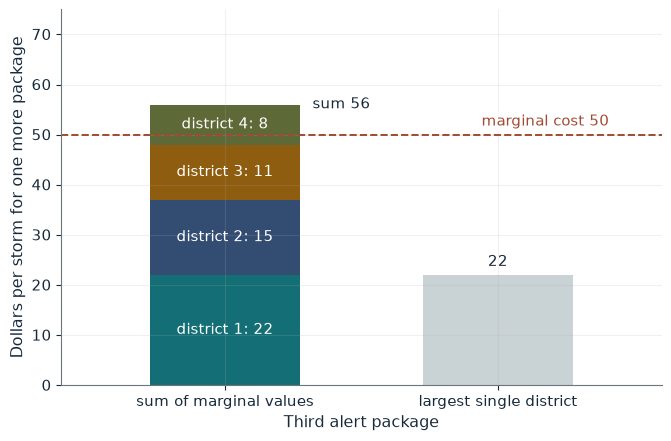

Sum of marginal values  56
Marginal cost           50
Surplus                 6
Largest single value    22
Package                 passes

Worked steps:
  1. MB = 22 + 15 + 11 + 8 = 56
  2. MB - MC = 56 - 50 = 6
  3. Largest single value 22 < 50: no district buys alone

The districts' marginal values sum to 22 + 15 + 11 + 8 = 56. 56 > 50, so the third package passes with surplus 6. No district would pay 50 alone: the largest single value is 22.


In [2]:
show(samuelson_picture(k='3', mc=50, s=0))

Change one input, `mc`, and hold the others at the book's values:

In [3]:
sweep(samuelson_picture, 'mc', [42, 50, 58], {'k': '3', 's': 5}, ['Sum of marginal values', 'Surplus', 'Package'])

mc | Sum of marginal values | Surplus | Package
42 | 61 | 19 | passes
50 | 61 | 11 | passes
58 | 61 | 3 | passes


The third package passes with surplus 6 although no district values it above 22. With a cost of 58 it needs the inland spillover of 5 to pass (61 > 58).

## 2. Quadratic funding rewards breadth

$$F_B=(4\sqrt{36})^2=(4\times6)^2=576$$

$$M_B=576-144=432$$

$$F_C=(9\times4)^2=1{,}296$$

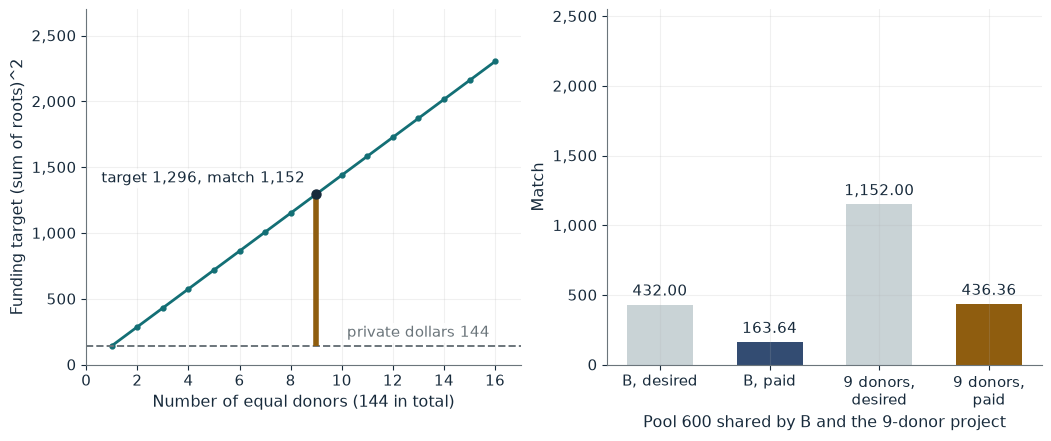

Funding target            1,296
Match                     1,152
Scaling factor beta       0.3788
B receives                163.64
9-donor project receives  436.36
Pool left over            0.00

Worked steps:
  1. Each of 9 gives 16; sqrt(16) = 4
  2. F = (9 x 4)^2 = 1,296; match = 1,296 - 144 = 1,152
  3. Desired matches: 432 + 1,152 = 1,584
  4. beta = 600 / 1,584 = 0.378788
  5. B: 432 x 0.378788 = 163.64; other: 1,152 x 0.378788 = 436.36

9 donors give 16 each for 144 in total. The target is (9 x 4)^2 = 1,296, so the match is 1,152: holding private money fixed, the target grows in proportion to the number of donors. The desired matches total 1,584, more than the pool of 600, so both are scaled by 0.3788: B receives 163.64 and the 9-donor project 436.36.


In [4]:
show(qf_picture(n=9, pool=600))

Change one input, `n`, and hold the others at the book's values:

In [5]:
sweep(qf_picture, 'n', [1, 4, 9, 16], {'pool': 600}, ['Funding target', 'Match', 'Scaling factor beta', 'B receives'])

n | Funding target | Match | Scaling factor beta | B receives
1 | 144 | 0 | 1.0000 | 432.00
4 | 576 | 432 | 0.6944 | 300.00
9 | 1,296 | 1,152 | 0.3788 | 163.64
16 | 2,304 | 2,160 | 0.2315 | 100.00


Holding 144 fixed, the target is 144 times the number of donors. With a 600 pool, B and C's desired matches of 432 and 1,152 are scaled by 0.3788 to 163.64 and 436.36.

## 3. Optimal club size: crowding versus cost sharing

$$u(n)=2{,}100-0.12n^2-\frac{72{,}000}{n}$$

$$0.24n=\frac{72{,}000}{n^2}$$

$$n^3=300{,}000$$

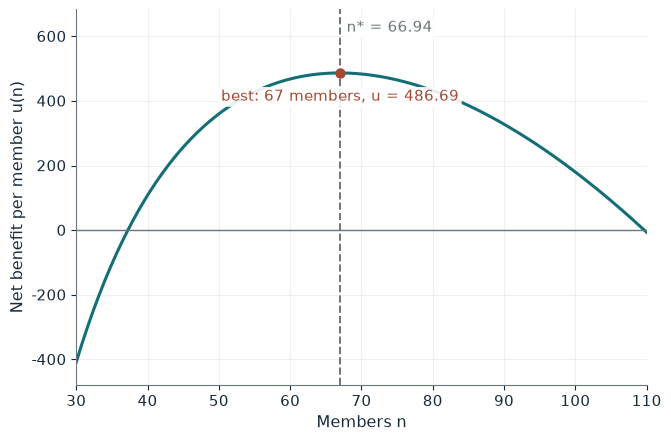

n^3 = C / 2a           300,000
Continuous optimum n*  66.94
Best whole club        67 members
Member net benefit u   486.69
Worth joining          yes

Worked steps:
  1. 2(0.12)n = 72,000/n^2 gives n^3 = 72,000 / 0.24 = 300,000
  2. n* = 300,000^(1/3) = 66.94
  3. u(66) = 2,100 - 522.72 - 1,090.91 = 486.37
  4. u(67) = 2,100 - 538.68 - 1,074.63 = 486.69
  5. Best whole club: 67 members

Congestion costs 0.12n^2 per member and cost sharing gives 72,000/n. Setting the marginal congestion loss 0.24n equal to the cost-sharing gain 72,000/n^2 gives n^3 = 300,000 and n* = 66.94. Comparing 66 and 67 members, the best whole club has 67, where u = 2100 - 538.68 - 1074.63 = 486.69. Each member nets a positive benefit, so the club is worth forming.


In [6]:
show(club_picture(cost=72000, a=0.12))

Change one input, `cost`, and hold the others at the book's values:

In [7]:
sweep(club_picture, 'cost', [48000, 72000, 96000], {'a': 0.12}, ['Continuous optimum n*', 'Best whole club', 'Member net benefit u'])

cost | Continuous optimum n* | Best whole club | Member net benefit u
48000 | 58.48 | 58 members | 868.73
72000 | 66.94 | 67 members | 486.69
96000 | 73.68 | 74 members | 145.58


The continuous optimum is 66.94 and the best whole club has 67 members with u = 486.69. A larger fixed cost raises the best size; with cost 96,000 and crowding 0.16 even the best club leaves each member -51.08.

## 4. Public goods and knowledge spillovers: grants net of diffusion costs

$$P=6(45{,}000)=270{,}000$$

$$V=270{,}000+230{,}000=500{,}000$$

$$C-P=420{,}000-270{,}000=150{,}000$$

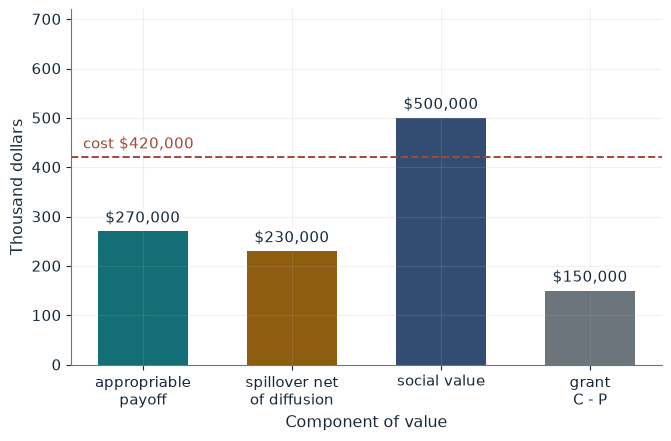

Private net             -$150,000
Social value            $500,000
Social net              $80,000
Grant to close the gap  $150,000
Verdict                 grant justified

Worked steps:
  1. Private net = 270,000 - 420,000 = -150,000
  2. Spillover net of diffusion = 230,000 - 0 = 230,000
  3. Social value = 270,000 + 230,000 = 500,000
  4. Social net = 500,000 - 420,000 = 80,000
  5. Grant = 420,000 - 270,000 = 150,000

The developer can collect 270,000 against a cost of 420,000, so it does not invest without help; a grant of 150,000 closes the gap. Society also gets 230,000 of spillover, for a social value of 500,000. In thousands, social net = 270 + 230 - 420 = 80. Social net value is $80,000, so the grant funds a project worth doing.


In [8]:
show(spillover_picture(s=230000, d=0))

Change one input, `d`, and hold the others at the book's values:

In [9]:
sweep(spillover_picture, 'd', [0, 110000], {'s': 230000}, ['Social value', 'Social net', 'Verdict'])

d | Social value | Social net | Verdict
0 | $500,000 | $80,000 | grant justified
110000 | $390,000 | -$30,000 | grant not justified


Without diffusion cost the grant funds a project worth 80,000 to society. Counting 110,000 of diffusion cost leaves a social net value of -30,000, so the same grant would fund a loss.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

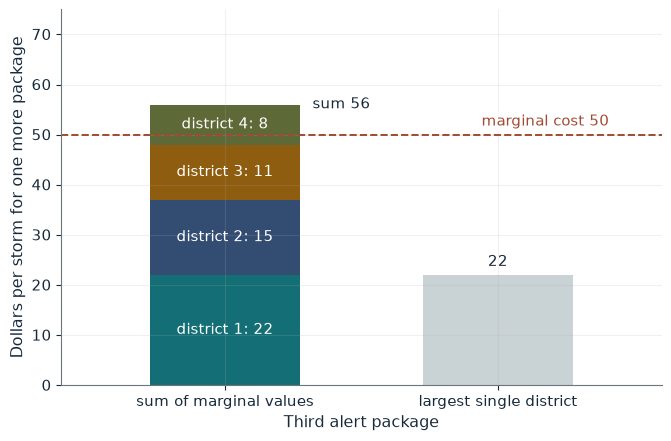

Sum of marginal values  56
Marginal cost           50
Surplus                 6
Largest single value    22
Package                 passes

Worked steps:
  1. MB = 22 + 15 + 11 + 8 = 56
  2. MB - MC = 56 - 50 = 6
  3. Largest single value 22 < 50: no district buys alone

The districts' marginal values sum to 22 + 15 + 11 + 8 = 56. 56 > 50, so the third package passes with surplus 6. No district would pay 50 alone: the largest single value is 22.


In [10]:
show(samuelson_picture(k='3', mc=50, s=0))

## Practice

**1.** With marginal cost 58 and the 5 spillover, does the third package pass?

<details><summary>Answer</summary>

56 + 5 = 61 > 58, so it passes; without the spillover 56 < 58 and it fails.

</details>

**2.** With nine donors of 16 each, what match is implied before the pool limit?

<details><summary>Answer</summary>

(9 x 4)^2 = 1,296, so the match is 1,296 - 144 = 1,152.

</details>

**3.** With diffusion cost 110,000, what is the social net value of the grant-funded project?

<details><summary>Answer</summary>

270,000 + (230,000 - 110,000) - 420,000 = -30,000.

</details>